In [216]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [217]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]
imagens= [1, 2, 4, 9, 10, 12, 11, 13,21, 22, 23, 25, 30, 32]

teste = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]
imagensTodas = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in imagens]


IMAGEM = teste

INDEX_IMG = 4 # Imagem a treinar/testar



Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. Por isso, segmenta-se pela cor, usando a cor do fundo como referência.   

Porque funciona: no fundo azul, B é bastante maior que R e G. Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. 

EXPLICAR os valores de tolerancia. as sombras baixam nao so o azul mas tbm as outras cores, por isso r e g precisa de ter alguma tolerancia, mas não tanto como o blue, pq o fundo é azul, etc.. 

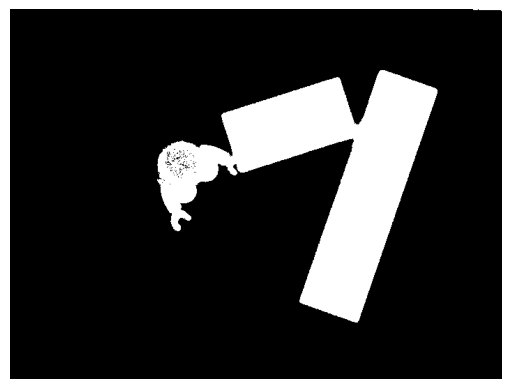

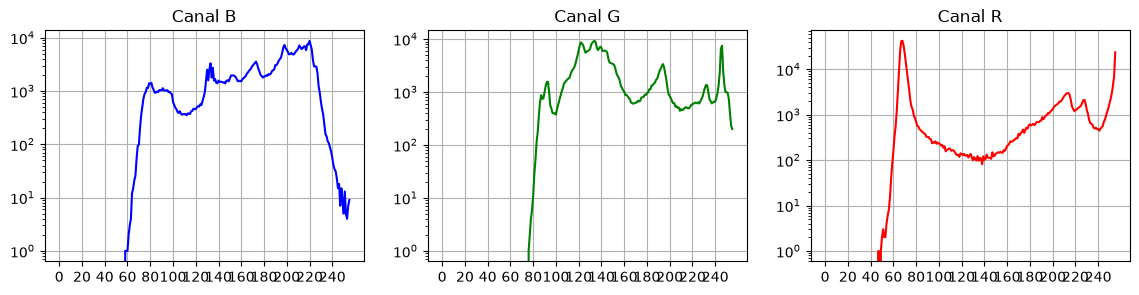

In [218]:
# Binarização


histogramas = [] # lista de listas com 3 histogramas (para cada canal)


def pecas(img):

    cor = []
    hists = []
    # cor dominante = bin mais cheio do histograma 3D

    # loop em que se vai ao canal 0,1 e 2 (rgb) e calcula-se um histograma para cada um dos canais 
    for i in range(3):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        cor.append(np.argmax(hist)) # da o valor do canal que tem mais pixeis associados 
        hists.append(hist)
    histogramas.append(hists)

    # os tres canais juntos formam a cor mais dominante, que corresponde ao fundo
    
    b, g, r = cor
    tol_b, tol_g, tol_r = 115, 73, 32 
    
    # tolerâncias aplicadas
    min = np.clip([b - tol_b, g - tol_g, r - tol_r], 0, 255)
    max = np.clip([b + tol_b, g + tol_g, r + tol_r], 0, 255)
    fundo = cv2.inRange(img, min, max)

    return 255 - fundo



# para relatorio
def mostraHist(hists):
    cores = ["blue", "green", "red"]
    nomes = ["B", "G", "R"]

    plt.figure(figsize=(14, 3))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.plot(hists[i], color=cores[i])     # hists[i], não hist
        plt.yscale("log")
        plt.xticks(range(0, 256, 20))
        plt.grid(True)
        plt.title("Canal " + nomes[i])
    plt.show()



binarizacao = [pecas(img) for img in imagensTodas]

# mostrar 1 para relatorio
plt.imshow(binarizacao[INDEX_IMG],cmap="gray")
plt.axis("off")
plt.show()

# index = 0
# for img in binarizacao:
#     cv2.imwrite(f'binarizacao/bin{index+1}.png', img)
#     index += 1

mostraHist(histogramas[0])


Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para fechar pequenos buracos, como os reflexos nos pinos do Lego.  

A cross ficava com vários pontinhos brancos onde não existiam peças. O rect era bem aproveitado se todas as peças estivessem direitas mas como não estão os cantos comecaçam a desaparecer e a ficar redondos. Então a ellipse foi a melhor opção, uma vez que não deformou as peças, nem acrescentou ruído extra. 

EXPLICAÇÃO DO AUMENTO DO KERNEL:
1. Erosão: encolhe as regiões brancas, podendo eliminar as mais pequenas.
2. Dilatação: volta a expandir as regiões que sobreviveram à erosão.
Com o kernel anterior de \(7\times7\), algumas manchas de ruído conseguiam sobreviver à erosão. Ao aumentares o kernel para \(22\times22\), a erosão torna-se muito mais agressiva, eliminando irregularidades maiores.

EXPLICAÇÃO DA ORDEM FECHO E DEPOIS ABERTURA:

A abertura (erosão → dilatação) remove o que é branco e mais pequeno que o kernel. Na peça com pinos, o branco entre os buracos são tiras estreitas, bem mais finas que 22 px. A erosão apaga-as por completo e os buracos crescem até se fundirem uns com os outros e com o fundo. A dilatação só consegue expandir o que sobreviveu, e o que foi apagado não volta. Por isso sobraria um esqueleto estranho. 

O fecho (dilatação → erosão) tapa o que é preto e mais pequeno que o kernel. Os buracos dos pinos são pretos e pequenos. A dilatação expande o branco e preenche-os totalmente, e a erosão seguinte devolve o contorno exterior à dimensão original. Os buracos não reaparecem, porque já não há preto no sítio onde estavam para a erosão recuperar.

A ordem de uso importa porque abertura e o fecho são assimétricos: cada um age sobre uma coisa diferente.
Com o fecho primeiro, a peça já chega à abertura como uma região sólida de largura, muito mais larga que o kernel de 22 px, e sobrevive intacta. Assim, a abertura passa a fazer só o pretendido, que é limpar ruído pequeno fora das peças.

(np.float64(-0.5), np.float64(705.5), np.float64(529.5), np.float64(-0.5))

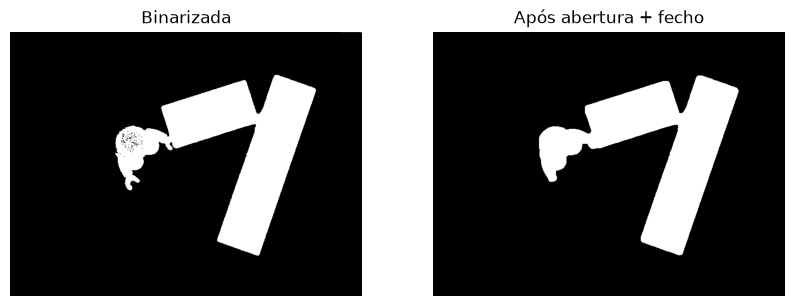

In [219]:
# Operadores Morfológicos

kernel_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (14,14)) # elemento estruturante da abertura
kernel_f= cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)) # do fecho


# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):

    fecho = cv2.morphologyEx(bin_, cv2.MORPH_CLOSE, kernel_f)   # fecho, tapa buracos pretos até 15px
    abertura = cv2.morphologyEx(fecho, cv2.MORPH_OPEN, kernel_a)    # abertura, apaga qq coisa branca mais estreita que 22px

    return abertura


img_limpo = [limpar(b) for b in binarizacao]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(binarizacao[INDEX_IMG], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

# index = 0
# for img in img_limpo:
#     cv2.imwrite(f'limpo/limpo{index+1}.png', img)
#     index += 1

Erodimos 5 vezes porque testámos a partir da função connectedComponents() e a partir do 5 já resultava o número final de peças. pq...(pesquisar potencial motivo). 

Utilizou-se uma erosão com elemento estruturante elíptico de 15×15 (raio 7 px), repetida 4 vezes. A erosão elimina estruturas mais estreitas do que o elemento, e as zonas de contacto entre peças são mais finas do que as próprias peças, pelo que desaparecem e as peças ficam em componentes ligados distintos. Com 4 iterações removem-se 28 px por lado, o que desfaz os contactos observados e preserva ~36 px na dimensão mais curta da menor peça (~92 px). O elemento elíptico é isotrópico, pelo que a perda de píxeis é a mesma em todas as direções e independente da orientação da peça, o que permite compensá-la com uma margem constante (56 px) nas medições.

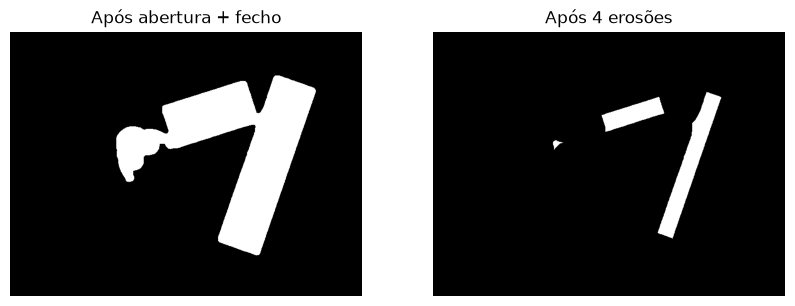

Imagem limpa:  1
Imagem com peças separadas:  3


In [220]:
# Separar peças juntas com Erosão

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15,15))

# A função separar aplica erosão a uma imagem limpa para separar as peças
def separar(limpa, it=4):
    return cv2.erode(limpa, kernel, iterations=it) 


img_sep   = [separar(l) for l in img_limpo]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(img_sep[INDEX_IMG], cmap="gray")
ax[1].set_title("Após 4 erosões")
ax[1].axis("off")
plt.show()


# para guardar as imgs
# index = 0
# for img in img_sep:
#     cv2.imwrite(f'separada/sep{index+1}.png', img)
#     index += 1


# ===== Testar a partir da etiquetação =====

resultado_limpo = [cv2.connectedComponents(tl) for tl in img_limpo] # lista de tuplos: (número de objetos, etiquetas)
resultado_sep= [cv2.connectedComponents(ts) for ts in img_sep] 
# [x][0] -> n objetos
# [x][1] -> etiquetas

print("Imagem limpa: ", resultado_limpo[INDEX_IMG][0] - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", resultado_sep[INDEX_IMG][0] - 1) 

### Etiquetação

A etiquetação consiste em atribuir uma etiqueta (identificador) única a cada objeto da imagem binarizada, ou seja, a cada conjunto de píxeis brancos ligados entre si, designado por componente conexa. Assim, cada peça passa a ser identificada e tratada individualmente, o que permite distingui-las umas das outras nas fases seguintes.

Para a etiquetação utilizaram-se as funções `cv2.findContours`, que determina o contorno de cada objeto, e `cv2.drawContours`, que desenha esses contornos sobre a imagem, permitindo verificar visualmente se a deteção está correta. Cada contorno detetado corresponde a um objeto e fica identificado pelo seu índice na lista devolvida, que funciona como etiqueta.

Optou-se por não utilizar `cv2.connectedComponents`, porque esta função devolve apenas uma imagem em que cada região tem uma etiqueta numérica, sem fornecer o contorno. No entanto, o contorno é indispensável para calcular as medidas de cada objeto, que servem de base à classificação das peças.

Número de objetos encontrados:  3


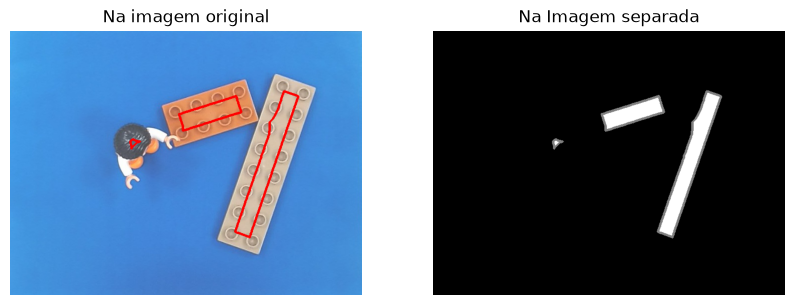

In [221]:
# Etiquetação

# findContours -> devolve uma lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos = [cv2.findContours(ts, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] for ts in img_sep]
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)
# [0] -> só para obter os contornos pq a função devolve um tuplo mas só precisamos do primeiro elemento


contorno = contornos[INDEX_IMG]
print("Número de objetos encontrados: ", len(contorno)) 

org = imagensTodas[INDEX_IMG].copy()
cv2.drawContours(org, contorno, -1, (0, 0, 255), 3)

sep = img_sep[INDEX_IMG].copy()
cv2.drawContours(sep, contorno, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

Na imagem original, os contornos aparecem mais pequenos do que as peças, uma vez que as erosões aplicadas reduziram as dimensões dos objetos. Apesar disso, observa-se que cada contorno se encontra totalmente contido na peça correspondente e que nenhum contorno toca noutro. Isto confirma que a erosão separou corretamente as peças que estavam em contacto, e o número de objetos detetados coincide com o número real de peças.

### Extração de Características

A extração de características consiste em calcular, para cada objeto etiquetado, um conjunto de medidas que o descrevam e permitam classificá-lo (2x2, 2x4, 2x6 ou 2x8) e rejeitar os objetos que não são peças retangulares. Esta fase é difícil porque as peças surgem em posições e orientações diferentes e, por vezes, como estavam em contacto, aparecem com um rasto da ligação anterior. Por isso, as medidas variam de imagem para imagem e não existe um valor único para cada classe.

A função `cv2.minAreaRect` calcula o retângulo de área mínima que contém o contorno, mesmo quando este se encontra rodado. Foi escolhida porque as suas dimensões não dependem da orientação da peça, ao contrário do `cv2.boundingRect`, que devolve um retângulo alinhado com os eixos da imagem. As peças são retângulos cuja razão entre o lado maior e o lado menor toma os valores teóricos 1, 2, 3 e 4, correspondentes a 2x2 (2/2), 2x4 (4/2), 2x6 (6/2) e 2x8 (8/2). Esta razão é, por isso, a medida principal de classificação.

Já a função `cv2.contourArea` calcula a área, em píxeis, da região delimitada pelo contorno, isto é, a área da peça e não a do retângulo. É proporcional ao número de pinos (4, 8, 12 e 16) e, como a câmara está fixa e paralela à mesa, a escala é constante.

Combinando as duas funções obtém-se a retangularidade, definida por:

`retangularidade = área do contorno / área do retângulo mínimo`

Numa peça retangular perfeita as duas áreas coincidem e o valor é 1. Numa peça com outra forma, o contorno preenche apenas parte do retângulo e o valor desce. Esta medida permite rejeitar as outras peças de Lego presentes na imagem, que apresentam valores inferiores aos das peças retangulares.

Como as erosões reduziram os contornos, as dimensões medidas são inferiores às reais, pelo que é necessário compensar esta perda. Cada iteração da erosão retira a cada lado do objeto um número de píxeis igual ao raio do elemento estruturante. Este é uma elipse de 15x15 píxeis, logo o raio é 7 (7 + 1 do centro + 7 = 15). Com 4 iterações perdem-se 4 × 7 = 28 px em cada lado. Como cada dimensão (largura ou comprimento) tem dois lados opostos, a perda total por dimensão é:

`margem = n.º de erosões × raio × 2 = 4 × 7 × 2 = 56 px`

Este valor é somado à largura e ao comprimento medidos.

A compensação é necessária porque a erosão retira um número fixo de píxeis a cada dimensão e não uma percentagem. Assim, a razão entre os lados altera-se e deixa de tomar os valores 1, 2, 3 e 4, o que invalidaria as referências usadas na classificação.

Criou-se função medir() que recebe um contorno e devolve as suas métricas. A retangularidade é calculada antes da compensação, porque a área do contorno é a da peça erodida e, por isso, a área do retângulo com que é comparada também tem de o ser. Se a margem fosse somada primeiro, compararia uma área reduzida com um retângulo já “reposto” e a retangularidade ficaria errada.

Depois de compensadas as dimensões, é necessário ordená-las, porque o `cv2.minAreaRect` pode devolver w como o lado curto ou como o lado comprido, consoante a rotação da peça. Com max e min, o valor maior corresponde sempre ao lado comprido e o menor ao lado curto. Assim, a razão maior / menor é sempre ≥ 1 e não depende da orientação.

In [222]:
# Extração de Características

margem = 4 * 7 * 2 # número de erosões * raio do elemento estruturante * lados 

# função que recebe um contorno e devolve as suas medidas num dicionário
def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    # (cx, cy): o centro do retângulo
    # (w, h): a largura e a altura desse retângulo

    area = cv2.contourArea(contorno) 

    ret = area / (w * h) # retangularidade

    w += margem # (*AQUI)
    h += margem # (*AQUI)

    maior, menor = max(w, h), min(w, h)

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret}

A função `numerar()` é uma função auxiliar que percorre os objetos detetados numa imagem, atribui um número a cada um e recolhe as respetivas métricas calculadas através da função medir(). Foi criada para reunir, para todas as imagens de treino, os valores medidos de cada objeto, de modo a compará-los com a classe real a que pertencem. Desta comparação resulta o intervalo de valores típico de cada classe (2x2, 2x4, 2x6 e 2x8), a partir do qual se definem os limiares usados na classificação.

--- lego1 ---
#0 | razão 1.00 | área 1709 | ret 0.93
#1 | razão 1.57 | área 6680 | ret 0.75
#2 | razão 2.00 | área 4474 | ret 0.95
#3 | razão 1.52 | área 3250 | ret 0.95
#4 | razão 2.01 | área 4168 | ret 0.96
#5 | razão 1.97 | área 4629 | ret 0.94
#6 | razão 3.94 | área 9733 | ret 0.95
#7 | razão 1.05 | área 1895 | ret 0.92
#8 | razão 1.04 | área 1592 | ret 0.95


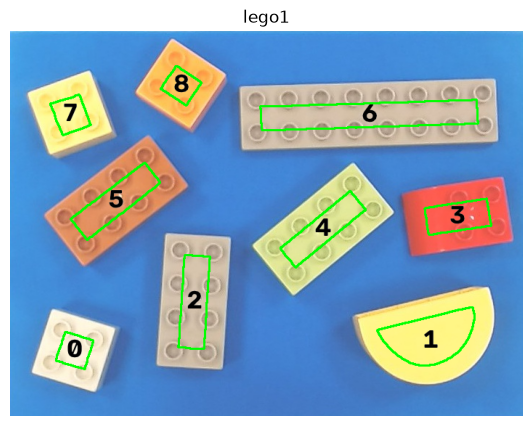

--- lego2 ---
#0 | razão 1.94 | área 4604 | ret 0.94
#1 | razão 1.28 | área 1858 | ret 0.88
#2 | razão 2.06 | área 4449 | ret 0.93
#3 | razão 3.98 | área 9388 | ret 0.95
#4 | razão 1.03 | área 1787 | ret 0.94
#5 | razão 1.04 | área 1562 | ret 0.95


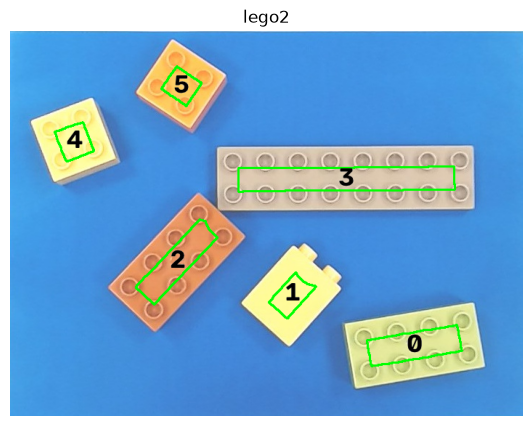

--- lego4 ---
#0 | razão 1.02 | área 1289 | ret 0.94
#1 | razão 1.99 | área 4303 | ret 0.97
#2 | razão 1.02 | área 1423 | ret 0.93


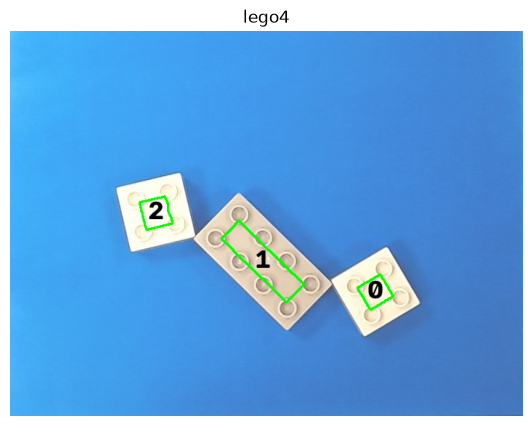

--- lego9 ---
#0 | razão 1.99 | área 4372 | ret 0.96
#1 | razão 1.92 | área 4189 | ret 0.86
#2 | razão 2.93 | área 8310 | ret 0.97
#3 | razão 3.94 | área 9784 | ret 0.96


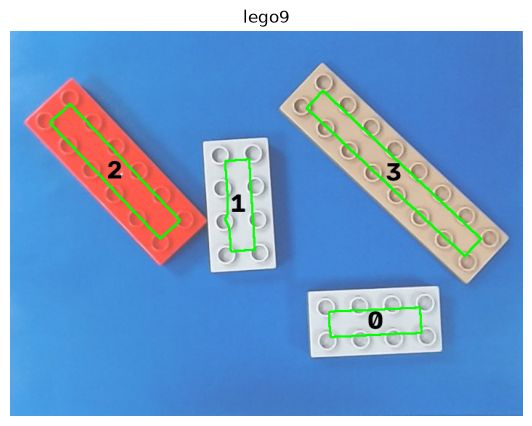

--- lego10 ---
#0 | razão 1.13 | área 137 | ret 0.47
#1 | razão 1.97 | área 4052 | ret 0.94
#2 | razão 3.79 | área 9281 | ret 0.82


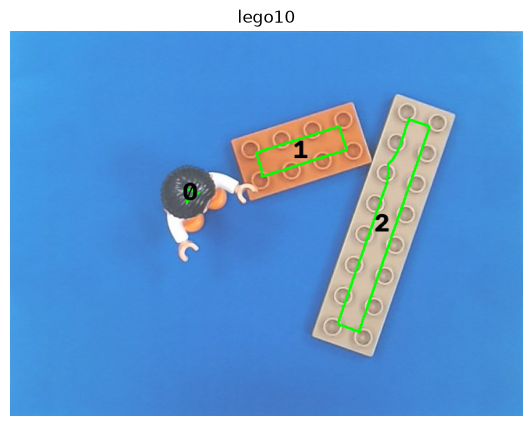

--- lego11 ---
#0 | razão 1.93 | área 4890 | ret 0.96
#1 | razão 3.65 | área 10314 | ret 0.81
#2 | razão 1.96 | área 4228 | ret 0.96


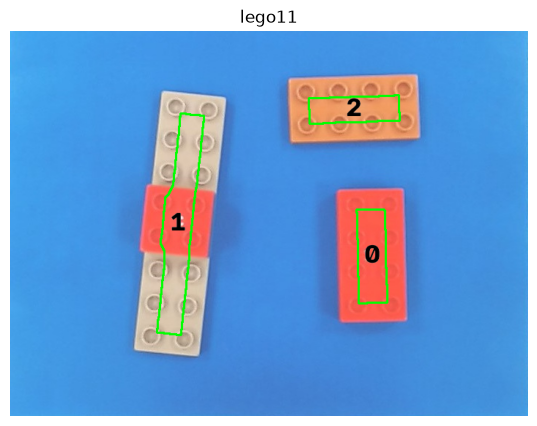

--- lego13 ---
#0 | razão 1.97 | área 4312 | ret 0.96
#1 | razão 2.01 | área 4069 | ret 0.96
#2 | razão 2.79 | área 9350 | ret 0.95
#3 | razão 1.53 | área 6036 | ret 0.72


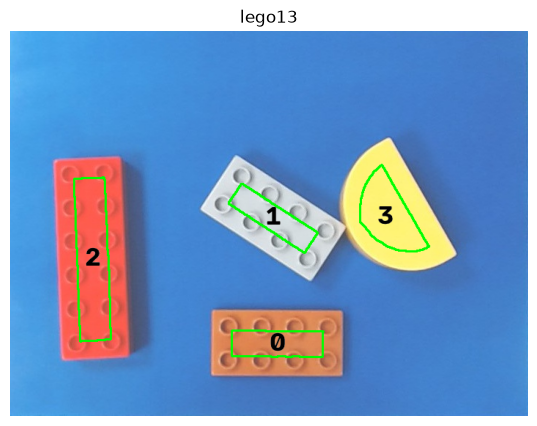

--- lego22 ---
#0 | razão 1.00 | área 1278 | ret 0.95
#1 | razão 1.01 | área 1368 | ret 0.99
#2 | razão 1.00 | área 1512 | ret 0.99
#3 | razão 1.02 | área 1334 | ret 0.94


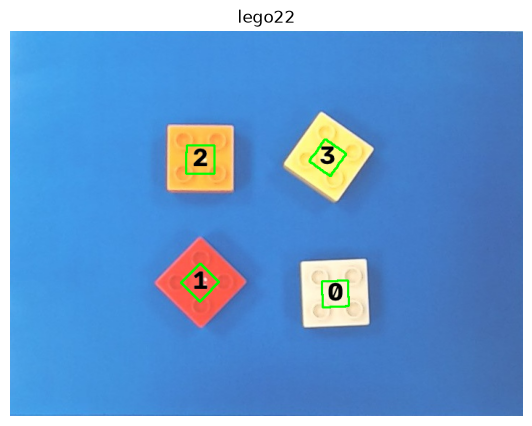

--- lego23 ---
#0 | razão 1.97 | área 4503 | ret 0.96
#1 | razão 1.96 | área 4504 | ret 0.96
#2 | razão 1.93 | área 4690 | ret 0.98
#3 | razão 1.93 | área 4968 | ret 0.95


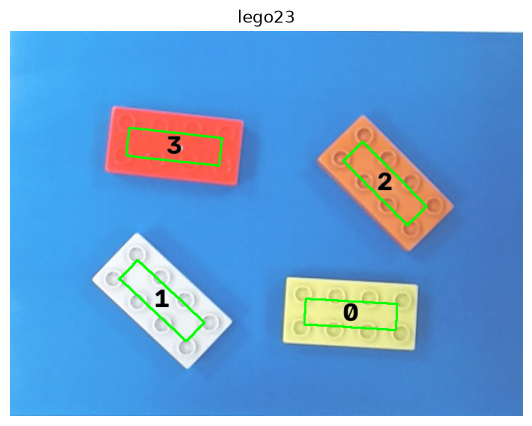

--- lego25 ---
#0 | razão 3.95 | área 9953 | ret 0.96


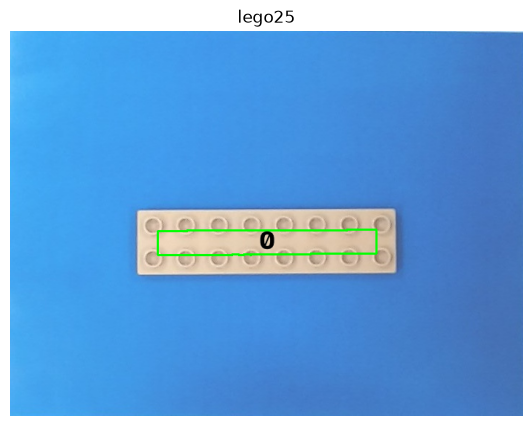

In [223]:
def numerar(n):
    i = imagens.index(n)
    vis = imagensTodas[i].copy()
    print(f"--- lego{n} ---")
    for k, c in enumerate(contornos[i]):        
        m = medir(c)
        cx, cy = int(m["centro"][0]), int(m["centro"][1])
        cv2.drawContours(vis, [c], -1, (0, 255, 0), 2)
        cv2.putText(vis, str(k), (cx - 10, cy + 10), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 6)  # contorno branco
        cv2.putText(vis, str(k), (cx - 10, cy + 10), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2)        # número
        print(f"#{k} | razão {m['razao']:.2f} | área {m['area']:.0f} | ret {m['retangularidade']:.2f}")
    plt.figure(figsize=(7, 5))
    plt.imshow(vis[:, :, ::-1])
    plt.title(f"lego{n}")
    plt.axis("off")
    plt.show()

for n in numTreino:
    numerar(n)

In [224]:
razoes = {"2x2": [1.00, 1.05, 1.04, 1.03, 1.04, 1.02, 1.02, 1.00, 1.01, 1.00, 1.02], 
          "2x4": [2.00, 2.01, 1.97, 1.94, 2.06, 1.99, 1.99, 1.92, 1.97, 1.93, 1.96, 1.97, 2.01, 1.97, 1.96, 1.93, 1.93], 
          "2x6": [ 2.93, 2.79], 
          "2x8": [3.94, 3.98, 3.94, 3.79, 3.65, 3.95]}

# retangularidade de todas as peças reais
rets   = [0.93, 0.95, 0.95, 0.96, 0.94, 0.95, 0.92, 0.95, 0.94, 0.93, 0.95, 0.94, 0.95, 0.94, 0.97, 0.93, 0.96, 0.86, 0.97,
          0.96, 0.94, 0.82, 0.96, 0.81, 0.96, 0.96, 0.96, 0.95, 0.95, 0.99, 0.99, 0.94, 0.96, 0.96, 0.98, 0.95, 0.96]   

lixo   = {"razao": [1.57, 1.28, 1.13, 1.53], 
          "ret": [0.75, 0.88, 0.47, 0.72]}

print("Ret min = ", min(rets))
for classe, v in razoes.items():
    print(f"{classe}: min = {min(v):.2f}, max = {max(v):.2f}")

Ret min =  0.81
2x2: min = 1.00, max = 1.05
2x4: min = 1.92, max = 2.06
2x6: min = 2.79, max = 2.93
2x8: min = 3.65, max = 3.98


A retangularidade mínima observada nas peças reais foi de 0,81, pelo que este valor foi usado como limiar inferior para aceitar um objeto como peça retangular.

Para cada tipo de peça determinou-se, a partir das imagens de treino, o intervalo de valores da razão (entre o mínimo e o máximo medidos), apresentado acima. No entanto, estes intervalos são justos demais, porque refletem apenas as imagens de treino, e é necessário dar-lhes uma folga para que a classificação funcione noutras imagens. Ao executar o algoritmo com as imagens de teste, verificou-se que algumas peças ficavam fora dos intervalos, e foi-se determinando quanto era necessário alargá-los.

Concluiu-se que a folga não podia ser um valor único para todas as classes. Se se subtraísse e somasse a mesma margem a todos os intervalos, esta teria de ser pelo menos 0,11 para que uma peça 2x6 de teste fosse aceite. Porém, com essa margem, o limite superior do 2x2 passaria de 1,05 para 1,16, e um objeto que não é uma peça, com razão 1,13 (imagem lego10), passaria a ser contado como 2x2.

Optou-se, por isso, por começar com uma margem de 0,04 em cada extremo do intervalo (mínimo − 0,04 e máximo + 0,04) e depois ajustar a folga de cada classe individualmente, acrescentando mais 0,04. Este alargamento foi particularmente importante no 2x6, porque as imagens de treino só continham duas peças desta classe. Com tão poucas amostras, os valores mínimo e máximo medidos representam mal a variação real, pelo que o intervalo obtido é demasiado estreito.

### Classificação

A classificação é a etapa final do trabalho e é nela que se avalia o desempenho do algoritmo. Consiste em atribuir cada objeto detetado a uma das classes (2x2, 2x4, 2x6 ou 2x8) com base nas métricas calculadas, ou em rejeitá-lo quando não corresponde a nenhuma peça retangular.

Para isso criou-se a função `classificar()`, que recebe as métricas de um objeto e compara-as com os intervalos definidos na secção anterior. O objeto é atribuído à classe cujo intervalo de razão contém o valor medido, desde que a retangularidade seja suficientemente elevada. Se nenhuma condição se verificar, o objeto é rejeitado, o que permite excluir as outras peças de Lego presentes na imagem.

Criou-se também a função `contar()`, que recebe os contornos de uma imagem e a imagem original correspondente. Esta função percorre os contornos e, para cada um, chama `medir()` para obter as métricas e `classificar()` para determinar a classe. No fim, conta quantas peças de cada classe estão presentes e escreve sobre a imagem original o texto com a classe atribuída, o que permite verificar visualmente o que foi identificado e como foi classificado.

Por fim, apresentam-se os resultados para todas as imagens de treino e de teste, comparando o resultado obtido com a realidade e comentando os casos em que o algoritmo funcionou bem e aqueles em que falhou.

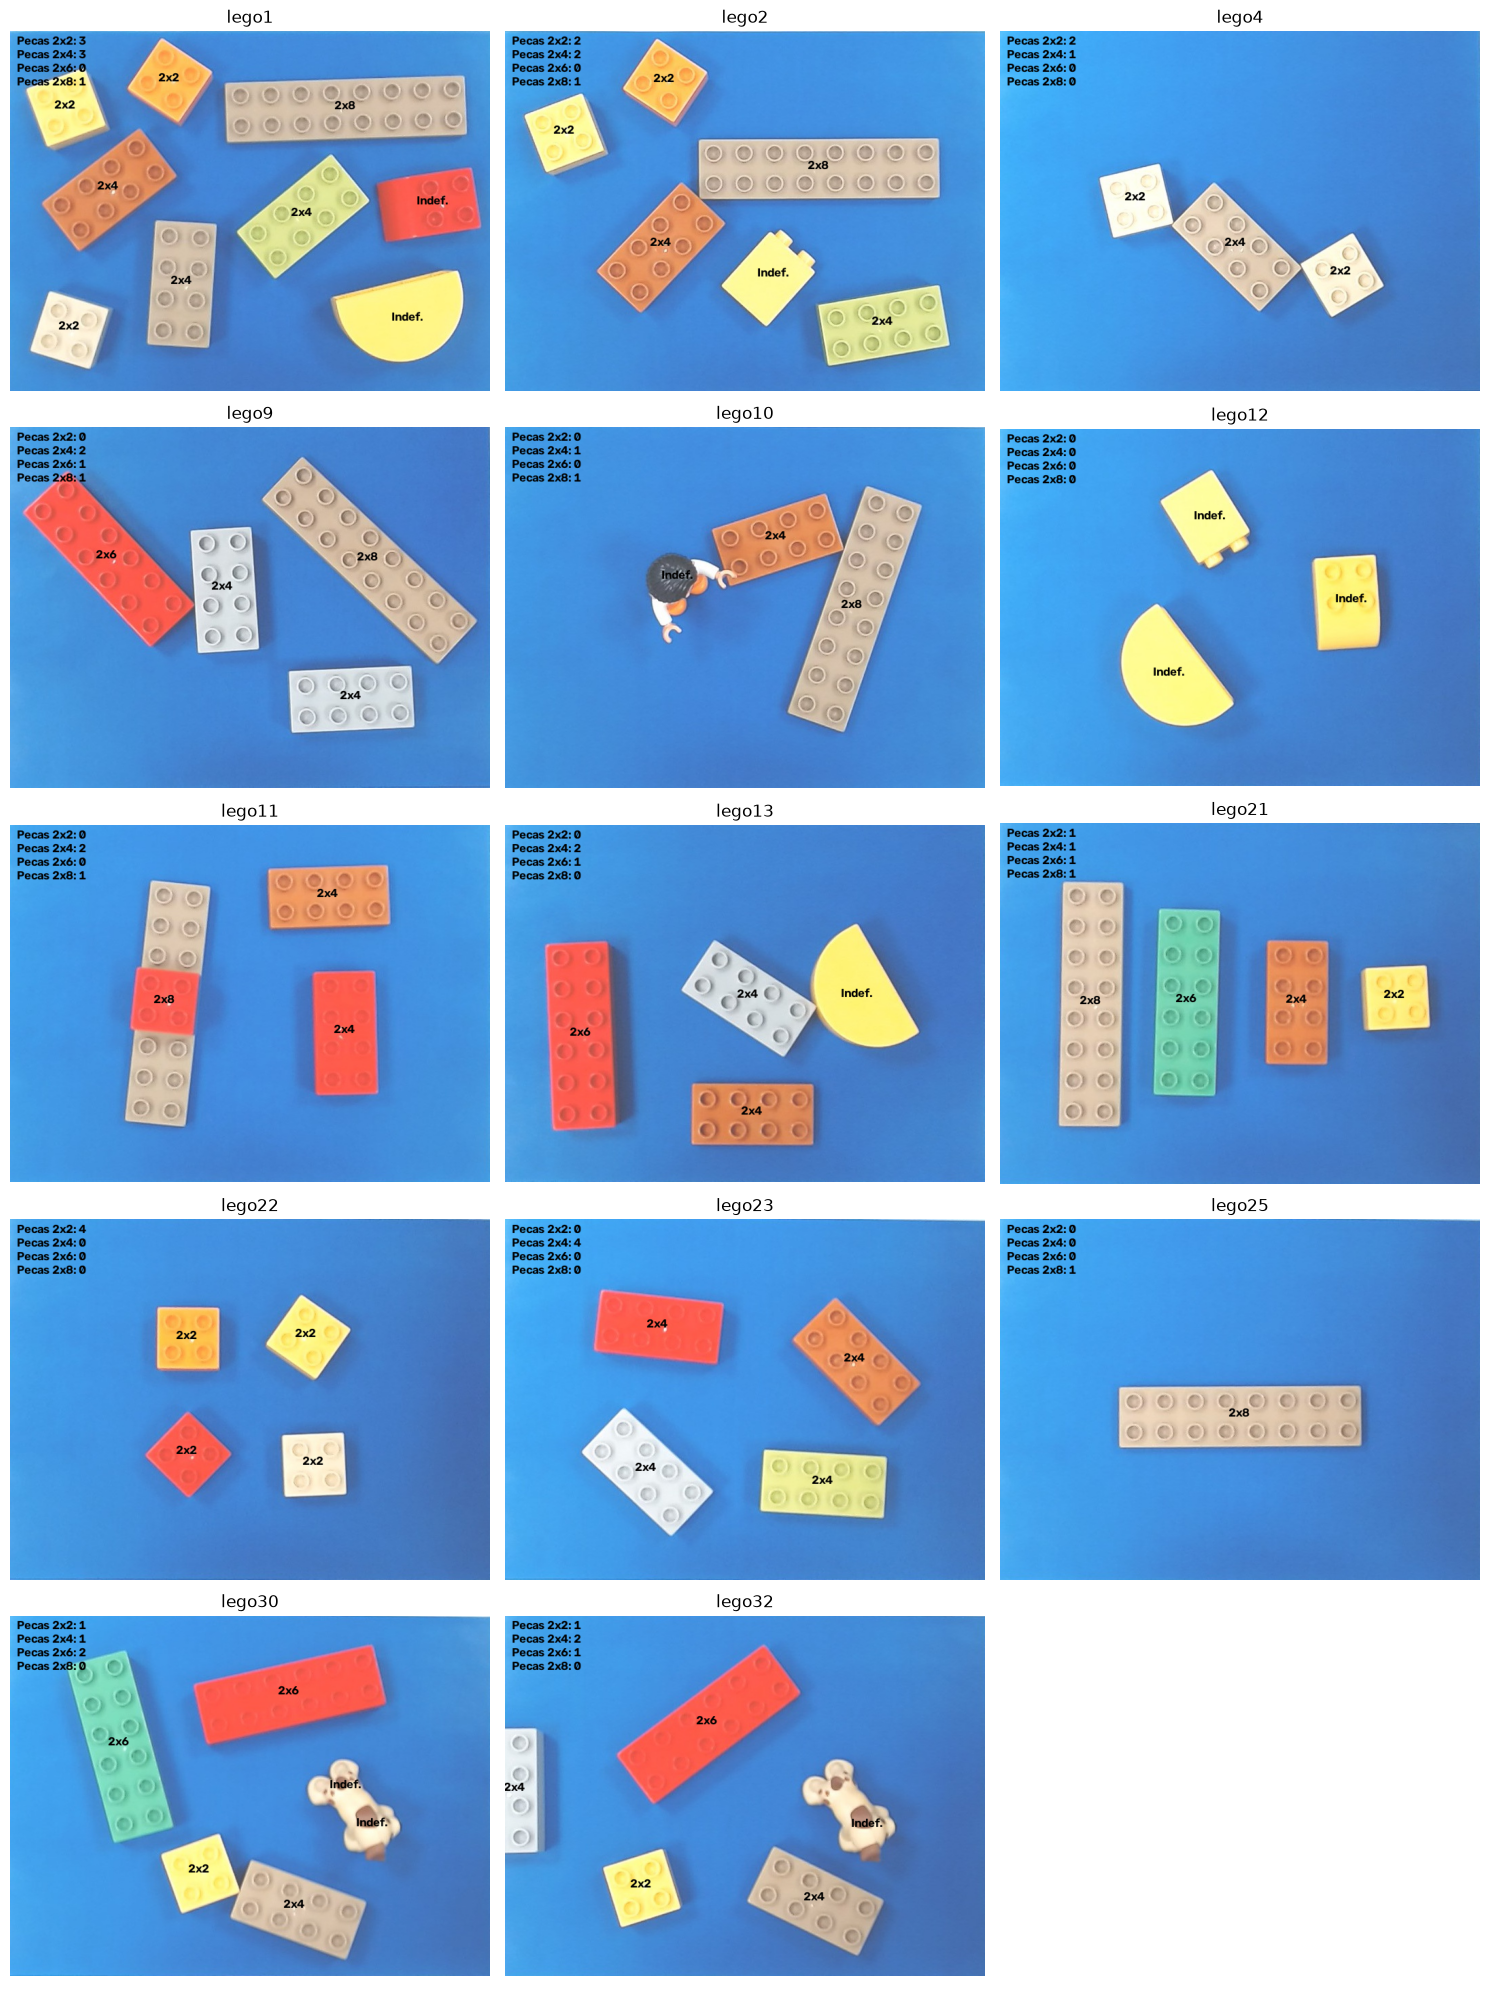

In [ ]:
# Classificação

def classificar(m):
    # rejeitar o que não é retangular (semicírculo, outras peças, restos da erosão)
    if m["retangularidade"] < 0.80:
        return None
    r = m["razao"]
    # classificar pela razão, com zonas de rejeição entre as classes
    if 0.96 <= r <= 1.09: # + 0.04
        return "2x2"
    elif 1.84 <= r <= 2.14: # + 0.08
        return "2x4"
    elif 2.67 <= r <= 3.05: # + 0.12
        return "2x6"
    elif 3.49 <= r <= 4.14: # + 0.16
        return "2x8"
    return None   # razão fora das classes 


# Escreve na imagem as peças identificadas
def contar(conts, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()

    for c in conts:
        m = medir(c) # métricas
        tipo = classificar(m) # classificação

        cx, cy = m["centro"]

        if tipo is None:
            cv2.putText(saida, "Indef.", (int(cx) - 17, int(cy)), # imagem, texto, posição
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) # fonte, tamanho, cor, espessura
            continue

        contagem[tipo] += 1
        
        cv2.putText(saida, tipo, (int(cx) - 17, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 

    # resumo no canto superior esquerdo
    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return saida


img_clasf = [contar(contornos[k], imagensTodas[k]) for k in range(len(contornos))]

colunas = 3
linhas = int(np.ceil(len(img_clasf) / colunas)) # arredonda para cima para caberem todas

fig, ax = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
ax = ax.flatten() # lista simples de eixos, qualquer que seja a grelha

for k, img in enumerate(img_clasf):
    ax[k].imshow(img[:, :, ::-1])
    ax[k].set_title(f"lego{imagens[k]}")
    ax[k].axis("off")

for k in range(len(img_clasf), len(ax)): # esconde os eixos que sobram na última linha
    ax[k].axis("off")

plt.tight_layout()
plt.show()

# salvar imagens 
# index = 0
# for img in img_clasf:
#     cv2.imwrite(f'classificado/clsf{index+1}.png', img)
#     index += 1

### Análise dos resultados

Na primeira imagem, a classificação foi muito boa, todas as peças retangulares foram identificadas corretamente e os restantes objetos foram rejeitados. Nesta imagem existe uma peça vermelha 2x2 que o sistema rejeitou. Como a peça tem altura, a sua face lateral é visível na imagem e passa a fazer parte da região segmentada, o que altera a forma e as dimensões do contorno, que deixam de corresponder à classe 2x2. Esta rejeição é preferível a uma classificação errada, porque a peça não é contada indevidamente noutra classe.

Nas imagens seguintes os resultados estão todos corretos. Destaca-se a lego12, que contém uma peça com o aspeto de uma 2x2, mas com uma curvatura que as restantes não têm. Essa curvatura faz com que o contorno preencha apenas parte do retângulo mínimo, pelo que a retangularidade fica abaixo do limiar e a peça é rejeitada, o que está correto.

Na lego11, o sistema identificou uma peça 2x8. Como a imagem é binarizada, as peças perdem a cor e deixam de ser distinguíveis entre si. Quando estão em contacto e a erosão não as separa, o conjunto é detetado como um único objeto, com dimensões compatíveis com a classe 2x8. Este resultado é coerente com a informação disponível, mas evidencia uma limitação do método, que depende apenas da forma e não da cor.

Na lego30, todas as peças foram identificadas corretamente, mas o texto “indefinido” aparece duas vezes sobre a zona da peça correta. Este efeito deve-se às 4 erosões com elemento estruturante de 15x15, que podem deixar pequenos resíduos do objeto. Estes resíduos originam contornos adicionais que não correspondem a nenhuma classe e, por isso, são rejeitados, sem afetar a contagem final.

Na última imagem, o sistema classificou como 2x4 uma peça cortada pelo limite da imagem, o que está de acordo com o que se observa visualmente. A peça foi aceite porque é retangular, com retangularidade superior a 0,80, e a sua área é coerente com o intervalo da classe 2x4.

### Conclusão

Concluindo, o sistema funcionou de forma correta e dentro do esperado nas imagens apresentadas, lidando bem com sombras, peças em contacto e objetos que não são peças retangulares. Apresenta, no entanto, algumas limitações: peças de cores diferentes em contacto podem ser detetadas como um único objeto (lego11) e a erosão pode originar contornos residuais, rejeitados como “indefinido” (lego30), embora estes não afetem a contagem final.